# Module 1 · Partie 2 : La régression linéaire univariée

> Cours d'**Analyse multivariée 2 : Data Mining & Machine Learning** (Prof. H. Soyeurt, Gembloux Agro-Bio Tech, 2026-2027).
> Sources : slides *Linear, Ridge, Lasso regressions*, syllabus *module1.pdf* §3.1, résolution *Module 1 - Lactoferrin* §4-5, cheatsheet du module.

### Objectifs d'apprentissage
À la fin de ce notebook, tu sauras :
1. écrire le modèle de régression linéaire univariée et définir **résidu**, **valeur prédite**, **intercept** et **pente** ;
2. dériver les **équations normales** des moindres carrés et retrouver $a = \bar y - b\bar x$ et $b = \mathrm{cov}(x,y)/s_x^2$ ;
3. calculer et interpréter **r**, **R²**, **MSE**, **RMSE** (et **SEP**, **R² ajusté**) à la main et avec R ;
4. utiliser `lm()`, lire **toute** la sortie de `summary()` et généraliser l'usage de `lm()` (formules, `predict`, `confint`, `anova`…) ;
5. choisir la meilleure variable spectrale pour prédire la lactoferrine à partir du **spectre de corrélation** ;
6. réaliser une **analyse des résidus** complète (4 graphes, test de Shapiro-Wilk, distance de Cook) et corriger le modèle par une **transformation log10**.

### Prérequis
Parties 0 (rappels R) et 1 (contrôle des données, transformation log10 de la lactoferrine).

### Sommaire
- 2.1 Le modèle univarié
- 2.2 Estimation par les moindres carrés (équations normales)
- 2.3 Qualité de l'ajustement : r, R², MSE, RMSE
- 2.4 Exemple « méthane » des slides (données simulées) : tout à la main puis avec `lm()`
- 2.5 La fonction `lm()` et la lecture de `summary()`
- 2.6 Application : lactoferrine et spectre MIR
- 2.7 Analyse des résidus
- 2.8 Transformation log10 de y
- 2.9 Généraliser `lm()` : formules, prédiction, intervalles
- Récapitulatif

In [1]:
# Packages utilisés dans ce notebook
suppressPackageStartupMessages({
  library(summarytools)  # descr()
  library(pander)        # tableaux "propres" (RMarkdown)
  library(knitr)         # kable()
})
options(repr.plot.width = 10, repr.plot.height = 6)  # taille des figures dans Jupyter

# Petite fonction utilitaire : afficher une sortie pander joliment dans Jupyter
# (hors Jupyter, par ex. dans RStudio, elle se contente d'appeler pander())
show_pander <- function(obj, ...) {
  if (isTRUE(getOption("jupyter.in_kernel")) && requireNamespace("IRdisplay", quietly = TRUE)) {
    IRdisplay::display_markdown(paste(capture.output(pander(obj, ...)), collapse = "\n"))
  } else pander(obj, ...)
}

---
## 2.1 Le modèle de régression linéaire univariée

Lorsque deux variables $x$ et $y$ présentent une **dépendance linéaire** et que l'on souhaite exprimer l'une en fonction de l'autre, on fait face à un problème de **régression linéaire**.

- $y$ = **variable à expliquer** (*variable to be explained*, *response*, *target*) ;
- $x$ = **variable explicative** (*explanatory / explaining variable*, *feature*).

Comme on dispose d'une cible $y$ à atteindre, c'est une méthode **supervisée** (cf. partie 0).

$$y_i = a + b\,x_i + e_i \qquad i = 1,\dots,n$$

> **Définitions**
> - $a$ : **ordonnée à l'origine** (*intercept*), valeur de $y$ quand $x = 0$ ;
> - $b$ : **coefficient de régression** (*slope*, pente) : variation de $y$ quand $x$ augmente d'une unité ;
> - $\hat y_i = a + b\,x_i$ : **valeur prédite** (*predicted / fitted value*) ;
> - $e_i = y_i - \hat y_i$ : **résidu** (*residual*), écart entre la valeur observée et la valeur prédite.

> **Attention** (cheatsheet) : le **résidu** (observé − prédit) n'est pas l'**erreur** (observé − vraie valeur, inconnue). Les résidus sont des *estimations* des erreurs.

Avec R, pour un vecteur $y$ et un vecteur $x$ :

$$\begin{bmatrix} y_1\\ y_2\\ \vdots\\ y_n\end{bmatrix} = a + b \begin{bmatrix} x_1\\ x_2\\ \vdots\\ x_n\end{bmatrix} + \begin{bmatrix} e_1\\ e_2\\ \vdots\\ e_n\end{bmatrix}$$

**Question posée par la régression** : *quelle est la relation entre x et y ?* On résume $y$ par $(\bar y, \sigma_y)$, $x$ par $(\bar x, \sigma_x)$, et on cherche la droite qui « colle » le mieux au nuage de points.

---
## 2.2 Estimation par les moindres carrés

### 2.2.1 Le critère
On cherche $a$ et $b$ tels que la droite **minimise la distance entre les observations et les prédictions**, c'est-à-dire la **somme des carrés des résidus** :

$$f(a,b) = \sum_{i=1}^n e_i^2 = \sum_{i=1}^n (y_i - \hat y_i)^2 = \sum_{i=1}^n (y_i - a - b\,x_i)^2$$

C'est la minimisation d'une somme de carrés qui donne son nom à la méthode : régression **des moindres carrés** (*least squares*, Legendre, ~1805). Mathématiquement, $a$ et $b$ sont ici les **inconnues** de la fonction $f$.

### 2.2.2 Les équations normales
Pour trouver l'extremum de $f(a,b)$, on annule ses dérivées partielles (et on vérifie avec les dérivées secondes qu'il s'agit bien d'un minimum : $f$ est une parabole « vers le haut » en $a$ et en $b$) :

$$\frac{\partial f}{\partial a} = -2\sum_{i=1}^n (y_i - a - b x_i) = 0 \qquad\Longleftrightarrow\qquad \sum_{i=1}^n (y_i - a - b x_i) = 0$$

$$\frac{\partial f}{\partial b} = -2\sum_{i=1}^n x_i\,(y_i - a - b x_i) = 0 \qquad\Longleftrightarrow\qquad \sum_{i=1}^n x_i (y_i - a - b x_i) = 0$$

C'est le **système des équations normales** : 2 équations linéaires, 2 inconnues.

### 2.2.3 Résolution (détaillée)
**Équation 1** : $\sum y_i - n a - b \sum x_i = 0 \;\Rightarrow\; \boxed{a = \bar y - b\,\bar x}$
→ la droite passe toujours par le **point moyen** $(\bar x, \bar y)$.

**Équation 2** : on remplace $a$ :
$$\sum x_i y_i - (\bar y - b\bar x)\sum x_i - b\sum x_i^2 = 0
\;\Rightarrow\; \sum x_i y_i - n\bar x\bar y = b\left(\sum x_i^2 - n\bar x^2\right)$$

Or $\sum x_i y_i - n\bar x \bar y = \sum (x_i-\bar x)(y_i - \bar y) = SPE$ (somme des produits des écarts) et $\sum x_i^2 - n\bar x^2 = \sum (x_i - \bar x)^2 = SCE_x$ (somme des carrés des écarts), d'où :

$$\boxed{b = \frac{\sum_{i=1}^n (x_i-\bar x)(y_i-\bar y)}{\sum_{i=1}^n (x_i-\bar x)^2} = \frac{SPE}{SCE_x} = \frac{\mathrm{cov}(x,y)}{s_x^2}}$$

> **Complément** : le rapport $\mathrm{cov}/s_x^2$ ne dépend pas du dénominateur choisi ($n$ ou $n-1$), pourvu qu'on utilise **le même** pour la covariance et la variance : il se simplifie.

### 2.2.4 La covariance
$$\mathrm{cov}(x,y) = \frac{1}{n-1}\sum_{i=1}^n (x_i-\bar x)(y_i-\bar y) = \frac{\displaystyle\sum_{i=1}^n x_i y_i - \frac{\sum_{i=1}^n x_i \sum_{i=1}^n y_i}{n}}{n-1}$$

> **Attention** : sur la slide « Univariate linear regression » la formule de calcul est écrite $\sum x_i y_i - \frac{\sum x_i \sum y_i}{n_{sample}-1}$ : il manque des parenthèses. La forme correcte est celle ci-dessus (on divise $\sum x_i \sum y_i$ par $n$, **puis** le tout par $n-1$). On le vérifie numériquement plus bas.

---
## 2.3 Qualité de l'ajustement : r, R², MSE, RMSE

### 2.3.1 Coefficient de corrélation de Pearson
$$r = R_{x,y} = \frac{\mathrm{cov}(x,y)}{s_x\,s_y}$$

Propriétés (syllabus §3.1) :
- $-1 \le r \le 1$, nombre **sans unité** mesurant l'**intensité du lien linéaire** ;
- $r = 1$ : tous les points sur une droite de pente positive ; $r = -1$ : pente négative ;
- droite parallèle à un axe, ou $r \approx 0$ : lien **linéaire** faible ou absent… mais cela **n'exclut pas un lien non linéaire** ;
- une corrélation indique que deux séries **évoluent en même temps**, pas une relation de **cause à effet**.

### 2.3.2 Coefficient de détermination R²
$$R^2 = r^2$$
**R² = part de la variabilité (somme des carrés des écarts) de y expliquée par la régression** sur x. $1 - R^2$ = part **non expliquée**. Il traduit aussi la linéarité entre x et y.

### 2.3.3 Variance résiduelle (MSE) et écart-type résiduel (RMSE)
La **variance des résidus**, appelée **erreur quadratique moyenne** (*mean square error*) :
$$MSE = \frac{1}{n}\sum_{i=1}^n (y_i - \hat y_i)^2 = \frac{1}{n}\sum_{i=1}^n e_i^2$$

On n'a pas besoin de calculer chaque résidu :
$$MSE = \frac{1}{n}\left[SCE_y - \frac{SPE^2}{SCE_x}\right] = s_y^2\,(1 - r^2) \qquad \left(\text{avec } s_y^2 = \tfrac{SCE_y}{n}\right)$$

*Démonstration :* $\frac{SPE^2}{SCE_x} = SCE_y \cdot \frac{SPE^2}{SCE_x\,SCE_y} = SCE_y \cdot r^2$, donc $MSE = \frac{SCE_y}{n}(1-r^2)$.

L'**écart-type résiduel** ou **RMSE** (*root mean square error*) $=\sqrt{MSE}$, dans **l'unité de y** :
$$0 \le RMSE \le s_y$$
- $RMSE = s_y$ si $r = 0$ (x n'explique rien) ;
- $RMSE = 0$ si $r = \pm 1$ (tous les points sur la droite, toute la variabilité de y est expliquée).

### 2.3.4 Tests de signification
Des tests **F** (et t) permettent de vérifier si $a$ et $b$ sont **significativement différents de 0**. Leurs détails, ainsi que les tests de **normalité** et d'**homoscédasticité** des résidus (conditions d'application), relèvent du cours de Statistiques appliquées (STAT2004-2005). On les utilisera via `summary()` et `shapiro.test()`.

---
## 2.4 Exemple « méthane » des slides : tout à la main

Les slides illustrent la régression avec la **production de méthane** (g/jour, $y$) d'une vache en fonction de la teneur du lait en acides gras **FA4-FA6** (% de la matière grasse, $x$) sur **20 échantillons**. Résultat présenté :
$$CH_4 = 136.23 \times \text{FA4-FA6} - 157.2 \qquad R^2 = 0.4121$$

> **Attention** : les données des slides ne sont **pas fournies**. On **simule** ci-dessous (avec `set.seed`) un jeu de 20 vaches **réaliste** (mêmes ordres de grandeur). Les valeurs numériques différeront donc légèrement de celles des slides, mais **tous les raisonnements sont identiques**. Le même jeu simulé sera réutilisé dans la partie 3.

In [2]:
# ---- Simulation du jeu "méthane" (20 vaches) ----
set.seed(2027)
n <- 20
FA4_6   <- rnorm(n, 4.6, 0.55)                          # % de la matière grasse
FA7_9   <- rnorm(n, 0.95, 0.12) + 0.08 * (FA4_6 - 4.6)
FA10_12 <- rnorm(n, 4.9, 0.7)
FA13_15 <- rnorm(n, 11.8, 1.1)
FA16_18 <- 100 - FA4_6 - FA7_9 - FA10_12 - FA13_15      # la somme fait 100 % !
CH4 <- -700 + 90 * FA4_6 + 600 * FA7_9 + 12 * FA10_12 + 10 * FA13_15 + rnorm(n, 0, 70)

methane <- data.frame(FA4_6, FA7_9, FA10_12, FA13_15, FA16_18, CH4)
head(round(methane, 2))
summary(methane$CH4)

,FA4_6,FA7_9,FA10_12,FA13_15,FA16_18,CH4
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,4.09,1.05,5.36,12.30,77.20,306.44
2,4.22,0.95,4.55,11.31,78.97,458.91
3,4.30,0.96,4.72,10.59,79.44,439.82
4,5.02,0.84,5.24,10.28,78.62,409.98
5,5.62,1.17,4.87,11.13,77.20,710.44
6,5.01,1.16,5.41,11.76,76.65,679.34


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  226.1   419.8   452.0   470.2   534.9   710.4 

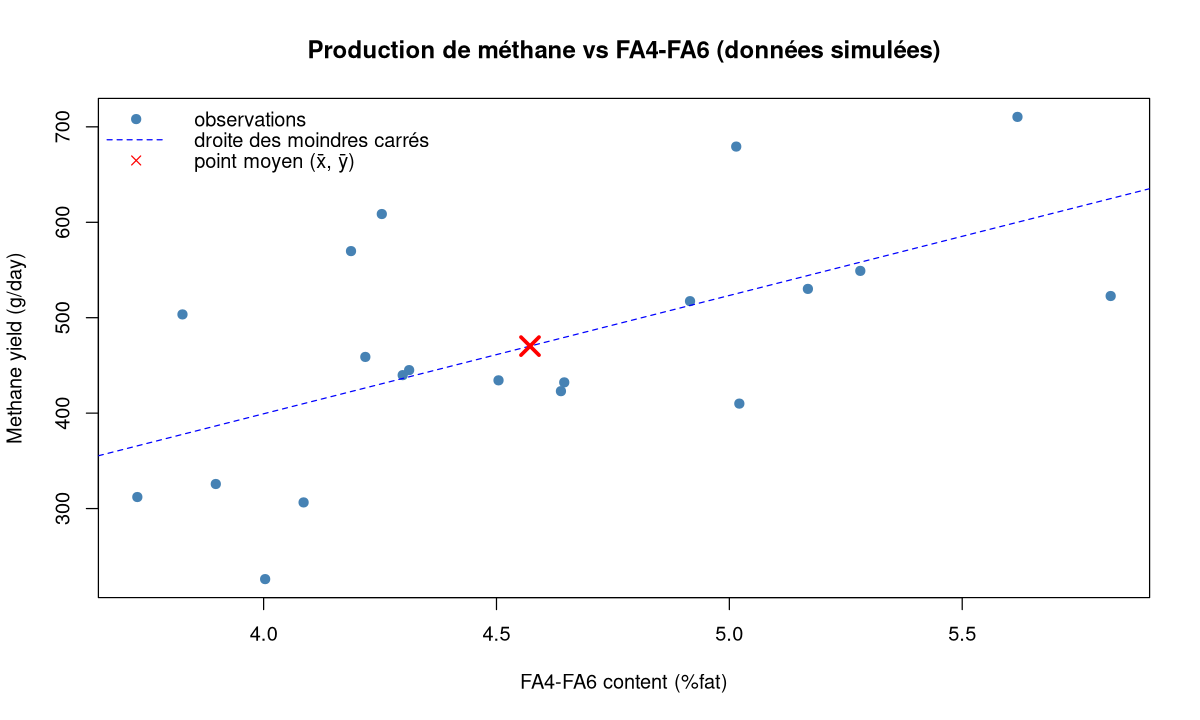

In [3]:
# Nuage de points + droite de régression (comme sur la slide)
x <- methane$FA4_6
y <- methane$CH4
plot(x, y, pch = 19, col = "steelblue", xlab = "FA4-FA6 content (%fat)",
     ylab = "Methane yield (g/day)", main = "Production de méthane vs FA4-FA6 (données simulées)")
abline(lm(y ~ x), lty = 2, col = "blue")
points(mean(x), mean(y), pch = 4, cex = 2, lwd = 3, col = "red")   # point moyen
legend("topleft", c("observations", "droite des moindres carrés", "point moyen (x̄, ȳ)"),
       pch = c(19, NA, 4), lty = c(NA, 2, NA), col = c("steelblue", "blue", "red"), bty = "n")

### 2.4.1 Calcul à la main des coefficients

In [4]:
n    <- length(y)
xbar <- mean(x); ybar <- mean(y)
SCEx <- sum((x - xbar)^2)                 # somme des carrés des écarts de x
SCEy <- sum((y - ybar)^2)                 # somme des carrés des écarts de y
SPE  <- sum((x - xbar) * (y - ybar))      # somme des produits des écarts

b <- SPE / SCEx                           # pente
a <- ybar - b * xbar                      # intercept
cat("b =", round(b, 3), "   a =", round(a, 3), "\n")

# Même chose via cov() et var() (dénominateur n-1 des deux côtés : il se simplifie)
cat("b via cov/var =", round(cov(x, y) / var(x), 3), "\n")

b = 123.979    a = -96.584 


b via cov/var = 123.979 


In [5]:
# Vérification de la formule de calcul de la covariance (version correcte)
cov_formule <- (sum(x * y) - sum(x) * sum(y) / n) / (n - 1)
c(cov_formule = cov_formule, cov_R = cov(x, y))

cov_formule       cov_R 
   44.62169    44.62169

### 2.4.2 r, R², MSE et RMSE à la main

In [6]:
r  <- cov(x, y) / (sd(x) * sd(y))
R2 <- r^2

yhat <- a + b * x                         # valeurs prédites
e    <- y - yhat                          # résidus

MSE_1   <- sum(e^2) / n                   # définition (1/n)
MSE_2   <- (SCEy - SPE^2 / SCEx) / n      # sans calculer les résidus
sy2_n   <- SCEy / n                       # variance de y avec 1/n (syllabus)
MSE_3   <- sy2_n * (1 - R2)               # MSE = s_y^2 (1 - r^2)

round(c(r = r, R2 = R2, MSE_1 = MSE_1, MSE_2 = MSE_2, MSE_3 = MSE_3,
        RMSE = sqrt(MSE_1), s_y = sqrt(sy2_n)), 4)

r        R2     MSE_1     MSE_2     MSE_3      RMSE       s_y 
   0.6031    0.3637 9194.3586 9194.3586 9194.3586   95.8872  120.2077

On retrouve bien $MSE_1 = MSE_2 = MSE_3$ et $0 \le RMSE \le s_y$.

> **Complément** : la somme des résidus vaut toujours 0 (c'est la 1re équation normale) et les résidus sont non corrélés avec $x$ (2e équation normale). Vérifie-le : `sum(e)` et `sum(x * e)` sont nuls (à l'arrondi machine près).

In [7]:
c(somme_residus = sum(e), somme_x_residus = sum(x * e))

somme_residus somme_x_residus 
  -2.273737e-13   -8.295586e-13

### Exercice 2.1 : la droite passe par le point moyen
Montre numériquement que la valeur prédite en $x = \bar x$ vaut exactement $\bar y$. Puis calcule la valeur prédite de méthane pour une vache dont le lait contient 5 % de FA4-FA6.

In [8]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
a + b * xbar ; ybar          # identiques
a + b * 5                    # prédiction pour FA4-FA6 = 5 %
```

Comme $a = \bar y - b\bar x$, on a $a + b\bar x = \bar y$ : la droite des moindres carrés passe toujours par $(\bar x, \bar y)$.

</details>

### Exercice 2.2 : que vaut le RMSE quand x n'explique rien ?
Génère une variable `bruit <- rnorm(20)` (indépendante de `y`), calcule la régression de `y` sur `bruit` à la main (a, b, r, RMSE) et compare le RMSE à $s_y$ (avec $1/n$). Que constates-tu ?

In [9]:
# À toi de jouer !
set.seed(1)
bruit <- rnorm(20)

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1)
bruit <- rnorm(20)
b0 <- cov(bruit, y) / var(bruit)
a0 <- mean(y) - b0 * mean(bruit)
r0 <- cor(bruit, y)
RMSE0 <- sqrt(mean((y - (a0 + b0 * bruit))^2))
c(r = r0, RMSE = RMSE0, s_y = sqrt(sum((y - mean(y))^2) / 20))
```

$r$ est proche de 0 (mais jamais exactement 0 à cause du hasard d'échantillonnage) et le RMSE est très proche de $s_y$ : on retrouve $RMSE = s_y\sqrt{1-r^2} \approx s_y$. La variable n'apporte (presque) aucune information.

</details>

### Exercice 2.3 : les 5 régressions univariées des slides
Les slides se demandent « *Can we improve the results ?* » et comparent 5 modèles univariés (un par groupe d'acides gras). Calcule le $R^2$ de la régression de `CH4` sur chacune des 5 colonnes FA de `methane` **en une seule ligne** grâce à `sapply()` et `cor()`. Quel groupe d'acides gras est le meilleur prédicteur ?

Rappel des slides (données réelles) : FA4-FA6 0.41 ; FA7-FA9 0.51 ; FA10-FA12 0.12 ; FA13-FA15 0.10 ; FA16-FA18 0.21.

In [10]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
round(sapply(methane[, 1:5], function(col) cor(col, methane$CH4)^2), 2)
```

En univarié, $R^2 = r^2$ : il suffit donc d'élever les corrélations au carré. Comme dans les slides, c'est **FA7-FA9** qui est le meilleur prédicteur individuel. La question naturelle suivante (partie 3) : peut-on faire mieux en combinant plusieurs variables ?

</details>

---
## 2.5 La fonction `lm()` et la lecture de `summary()`

> **Fonction R** : `lm(formula, data, subset, weights, na.action, ...)`
>
> | Argument | Rôle |
> |---|---|
> | `formula` | modèle sous la forme `y ~ x` (« y expliqué par x ») ; intercept inclus par défaut |
> | `data` | data.frame où chercher les variables de la formule (facultatif si elles existent dans l'environnement) |
> | `subset` | sous-ensemble de lignes à utiliser (ex. `subset = -c(57, 120)`) |
> | `weights` | poids des observations (moindres carrés pondérés) |
> | `na.action` | traitement des NA (`na.omit` par défaut) |
>
> **Renvoie** un objet de classe `"lm"` (une liste) : `coefficients`, `residuals`, `fitted.values`, `df.residual`, `call`, `model`… On l'exploite avec les fonctions **génériques** `summary()`, `plot()`, `coef()`, `fitted()`, `resid()`, `predict()`, `confint()`, `anova()`, `AIC()`.

In [11]:
reg_ch4 <- lm(CH4 ~ FA4_6, data = methane)
reg_ch4                       # affichage minimal : l'appel et les coefficients
coef(reg_ch4)                 # identiques au calcul à la main (a, b)
c(a = a, b = b)


Call:
lm(formula = CH4 ~ FA4_6, data = methane)

Coefficients:
(Intercept)        FA4_6  
     -96.58       123.98  


(Intercept)       FA4_6 
  -96.58448   123.97852

a         b 
-96.58448 123.97852

In [12]:
summary(reg_ch4)


Call:
lm(formula = CH4 ~ FA4_6, data = methane)

Residuals:
    Min      1Q  Median      3Q     Max 
-173.66  -56.80  -11.56   51.99  177.87 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)   
(Intercept)   -96.58     178.15  -0.542  0.59436   
FA4_6         123.98      38.65   3.208  0.00488 **
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 101.1 on 18 degrees of freedom
Multiple R-squared:  0.3637,	Adjusted R-squared:  0.3284 
F-statistic: 10.29 on 1 and 18 DF,  p-value: 0.00488


### 2.5.1 Lecture détaillée de `summary()` (cf. cheatsheet)

| Élément | Signification |
|---|---|
| `Call` | la formule utilisée |
| `Residuals` | min, Q1, médiane, Q3, max des résidus : la médiane doit être proche de 0 et la distribution à peu près symétrique |
| `Estimate` | les coefficients estimés : `(Intercept)` = $a$, ligne de la variable = $b$ |
| `Std. Error` | erreur standard du coefficient : **incertitude** de son estimation. Plus elle est petite relativement à l'estimate, plus le coefficient est précis |
| `t value` | $= \text{Estimate}/\text{Std. Error}$ : plus $\lvert t\rvert$ est grand, plus le coefficient s'écarte de 0. En pratique, $\lvert t\rvert > 2$ est déjà bon signe |
| `Pr(>|t|)` | **p-value** : probabilité d'observer un $t$ aussi extrême si le vrai coefficient était nul ($H_0 : \beta = 0$). $p < 0.05$ → coefficient significatif. Les étoiles (`***`, `**`, `*`, `.`) résument le seuil |
| `Residual standard error` | écart-type résiduel $= \sqrt{\sum e_i^2/(n-k-1)}$, dans **l'unité de y** : erreur « typique » de prédiction. Suivi des **degrés de liberté** $n - k - 1$ |
| `Multiple R-squared` | $R^2$ : part de la variance de y expliquée |
| `Adjusted R-squared` | $R^2$ pénalisé par le nombre de paramètres : sert à **comparer des modèles de complexités différentes**. $R^2$ augmente **toujours** quand on ajoute une variable ; le $R^2$ ajusté n'augmente **que si** la variable améliore vraiment le modèle |
| `F-statistic` | test global : au moins un coefficient (hors intercept) ≠ 0 ? En univarié, $F = t^2$ |

> **Attention** : le *Residual standard error* de R divise par $n - k - 1$ (ici $n-2$, les **degrés de liberté**) et non par $n$ comme le $MSE$ du syllabus. Pour de grands $n$, la différence est négligeable.

In [13]:
s <- summary(reg_ch4)
# Ce que contient l'objet summary (une liste) :
names(s)
s$coefficients                       # le tableau des coefficients (matrice)
c(sigma = s$sigma, R2 = s$r.squared, adjR2 = s$adj.r.squared)
# Le "Residual standard error" recalculé à la main :
sqrt(sum(resid(reg_ch4)^2) / reg_ch4$df.residual)
# En univarié : F = t^2
c(F = unname(s$fstatistic[1]), t_carre = s$coefficients[2, 3]^2)

[1] "call"          "terms"         "residuals"     "coefficients" 
 [5] "aliased"       "sigma"         "df"            "r.squared"    
 [9] "adj.r.squared" "fstatistic"    "cov.unscaled"

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-96.58448,178.15078,-0.5421502,0.594363952
FA4_6,123.97852,38.65119,3.2076246,0.004879992


sigma          R2       adjR2 
101.0740027   0.3637070   0.3283574

[1] 101.074

F  t_carre 
10.28886 10.28886

### Exercice 2.4 : recalculer la t value et la p-value
À partir de `s$coefficients`, recalcule la `t value` de la pente puis sa p-value bilatérale avec `pt()` (loi de Student à `reg_ch4$df.residual` degrés de liberté).

In [14]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
est <- s$coefficients[2, "Estimate"]
se  <- s$coefficients[2, "Std. Error"]
t_val <- est / se
p_val <- 2 * pt(-abs(t_val), df = reg_ch4$df.residual)
c(t = t_val, p = p_val)
```

On retrouve exactement les colonnes `t value` et `Pr(>|t|)` du `summary()`. La p-value est bilatérale (d'où le facteur 2) car $H_1 : \beta \ne 0$.

</details>

---
## 2.6 Application : prédire la lactoferrine à partir du spectre MIR

Rappel (partie 1) : `lactoferrin.csv` contient **178 échantillons de lait** (lignes) et **1062 colonnes** : `V1` = identifiant, `V2`…`V1061` = **1060 points du spectre moyen infrarouge** (FT-MIR), `V1062` = teneur en **lactoferrine** (mg/L de lait).

Le nombre de variables explicatives (*features*) est très élevé (1060). **Comment choisir x ?** Intuitivement : on calcule la **corrélation entre la lactoferrine et chaque point spectral** et on prend le plus corrélé → **modèles univariés**.

In [15]:
# Lecture (cf. partie 0) - dans RStudio on ferait d'abord setwd("chemin/vers/Module1")
lactoferrin <- read.table(file = "../lactoferrin.csv", sep = ";")
dim(lactoferrin)

y <- data.frame(lactoferrin[, 1062])   # data.frame pour pouvoir nommer la colonne
names(y) <- c("lactoferrin")
stat <- descr(y, transpose = TRUE)     # summarytools
# On extrait quelques éléments avec $ (sous-indexer stat[, ...] pose problème à print() de summarytools)
round(c(Mean = stat$Mean, SD = stat$Std.Dev, Min = stat$Min, Median = stat$Median,
        Max = stat$Max, CV = stat$CV), 3)

[1]  178 1062

Mean       SD      Min   Median      Max       CV 
 206.746  301.694    7.694   90.468 2038.267    1.459

### 2.6.1 Le spectre de corrélation (méthode du cours)
La résolution calcule **toute** la matrice de corrélation des colonnes 2 à 1062 (spectre + lactoferrine), soit une matrice 1061 × 1061, puis garde les 1060 premières lignes de la **dernière colonne** (corrélation de chaque point spectral avec la lactoferrine).

[1] 1061 1061

V2            V3            V4            V5            V6 
-0.0064442305 -0.0042421484  0.0001943272  0.0082033796  0.0161827309 
           V7 
 0.0227708556

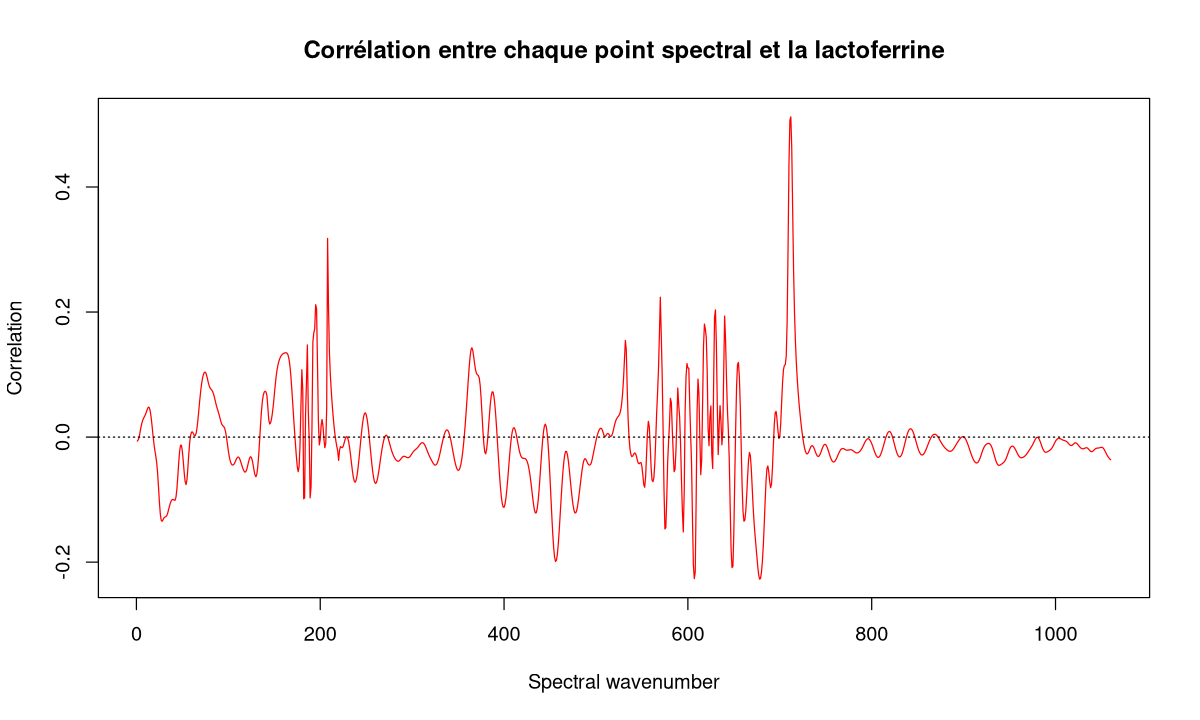

In [16]:
correlation <- cor(lactoferrin[, 2:1062])     # matrice 1061 x 1061 (sans l'ID)
dim(correlation)
correlation <- correlation[1:1060, 1061]      # 1060 premières lignes, colonne lactoferrine
head(correlation)

par(mfrow = c(1, 1))
plot(correlation, type = "l", col = "red", xlab = "Spectral wavenumber",
     ylab = "Correlation", main = "Corrélation entre chaque point spectral et la lactoferrine")
abline(h = 0, lty = 3)

> **Complément — méthode plus efficace** : on n'a besoin que d'**une** colonne de la matrice. `cor(X, y)` calcule directement la corrélation de chaque colonne de `X` avec `y` (1060 corrélations au lieu de 1061² ≈ 1.1 million). C'est l'approche du `homework1.R`.

In [17]:
correlation_bis <- cor(lactoferrin[, 2:1061], lactoferrin[, 1062])[, 1]
all.equal(correlation, correlation_bis)          # mêmes valeurs

[1] TRUE

### 2.6.2 Le point spectral le plus corrélé

In [18]:
cormax  <- max(abs(correlation))                         # corrélation max en valeur absolue
namemax <- names(correlation[abs(correlation) == cormax]) # nom de la variable correspondante
cormax; namemax

[1] 0.5121514

[1] "V713"

> **Attention — piège de la résolution/cheatsheet** : elles écrivent `names(correlation[correlation == cormax])` **sans** `abs()`. Ça marche ici parce que la corrélation maximale est **positive** (0.512). Si la plus forte corrélation était négative (ex. −0.6), `correlation == 0.6` ne trouverait rien (`character(0)`). Le `homework1.R` corrige avec `abs(correlation) == cormax`. Encore plus simple : `names(which.max(abs(correlation)))`.

On veut ensuite **classer** les corrélations. La fonction `order()` renvoie les **positions** qui trient un vecteur par ordre **croissant** : le dernier élément est donc la position de la plus forte corrélation absolue.

> **Fonction R** : `order(..., decreasing = FALSE)` renvoie la permutation des **indices** qui trie le vecteur (≠ `sort()`, qui renvoie les **valeurs** triées). Exemple : `order(c(30, 10, 20))` → `2 3 1`.

In [19]:
ordercorrelation <- order(abs(correlation))   # positions, de la plus faible à la plus forte |r|
tail(ordercorrelation)                        # la dernière = 712 (point spectral V713)
correlation[ordercorrelation[1060]]

[1] 208 714 710 713 711 712

V713 
0.5121514

**Le décalage +1** : la position 712 dans le vecteur `correlation` correspond au 712e point spectral… qui est stocké dans la **colonne 713** du data.frame `lactoferrin`, car la colonne 1 contient l'identifiant. D'où le `+1` :

In [20]:
x <- lactoferrin[, ordercorrelation[1060] + 1]   # +1 car sampleID en colonne 1
y <- as.matrix(y$lactoferrin)  # matrice à 1 colonne (pour dim/nrow)
x <- as.matrix(x)
dim(x); dim(y)

[1] 178   1

[1] 178   1

### 2.6.3 La régression univariée `reg1`

In [21]:
reg1 <- lm(y ~ x)
summary(reg1)


Call:
lm(formula = y ~ x)

Residuals:
    Min      1Q  Median      3Q     Max 
-449.48 -133.33  -50.53   71.21 1582.86 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   872.59      86.39  10.100  < 2e-16 ***
x            3754.91     474.66   7.911 2.73e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 259.9 on 176 degrees of freedom
Multiple R-squared:  0.2623,	Adjusted R-squared:  0.2581 
F-statistic: 62.58 on 1 and 176 DF,  p-value: 2.729e-13


La résolution affiche le résultat avec `pander()`, qui produit un joli tableau dans RStudio/RMarkdown. Dans Jupyter, `pander` écrit du Markdown brut ; notre petite fonction `show_pander()` le convertit en tableau :

In [22]:
panderOptions("table.style", "simple")   # voir ?panderOptions
show_pander(summary(reg1))



     &nbsp;        Estimate   Std. Error   t value   Pr(>|t|)  
----------------- ---------- ------------ --------- -----------
 **(Intercept)**    872.6       86.39       10.1     3.309e-19 
      **x**          3755       474.7       7.911    2.729e-13 



 Observations   Residual Std. Error   $R^2$    Adjusted $R^2$ 
-------------- --------------------- -------- ----------------
     178               259.9          0.2623       0.2581     

Table: Fitting linear model: y ~ x


**Interprétation** (résolution + cheatsheet) :
- Équation : $\widehat{\text{lactoferrine}} = 872.6 + 3755 \times V713$.
- Les deux coefficients sont très significatifs ($p \ll 0.05$).
- **176 degrés de liberté** = 178 observations − 2 paramètres estimés (intercept + pente).
- *Residual standard error* = **259.9 mg/L** : en moyenne, le modèle se trompe d'environ ±260 mg/L. C'est énorme comparé à la médiane (90 mg/L) !
- $R^2 = 0.2623$ : la longueur d'onde sélectionnée n'explique que **26 %** de la variabilité de la lactoferrine.

### 2.6.4 R², SEP et R² ajusté calculés à la main (résolution)

$$R^2 = \mathrm{cor}(y, \hat y)^2 \qquad SEP = \sqrt{\frac{\sum (\hat y_i - y_i)^2}{n - k - 1}} \qquad R^2_{adj} = 1 - \frac{(1 - R^2)(n-1)}{n - k - 1}$$

avec $k$ = nombre de paramètres estimés **hors intercept**. Le **SEP** (*standard error of prediction*) calculé ainsi sur les données de calibration est exactement le *Residual standard error*.

In [23]:
R2_1    <- cor(y, reg1$fitted.values)^2
SEP_1   <- sqrt(sum((reg1$fitted.values - y)**2) / reg1$df.residual)
k       <- 1                                  # nb de paramètres estimés hors intercept
adjR2_1 <- 1 - ((1 - R2_1) * (length(y) - 1)) / (length(y) - k - 1)
c(R2 = R2_1, SEP = SEP_1, adjR2 = adjR2_1, df = reg1$df.residual)

R2         SEP       adjR2          df 
  0.2622990 259.8590305   0.2581075 176.0000000

### Exercice 2.5 : le 2e meilleur point spectral
1. Quel est le nom du **2e** point spectral le plus corrélé (en valeur absolue) avec la lactoferrine ?
2. Ajuste la régression de `y` sur ce point (`reg_2e`) et compare son $R^2$ à celui de `reg1`.
3. Pourquoi les deux $R^2$ sont-ils si proches ? (indice : regarde où ces deux points se situent dans le spectre)

In [24]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
names(correlation)[ordercorrelation[1059]]          # "V712"
x2 <- as.matrix(lactoferrin[, ordercorrelation[1059] + 1])
reg_2e <- lm(y ~ x2)
c(R2_reg1 = summary(reg1)$r.squared, R2_reg_2e = summary(reg_2e)$r.squared)
cor(x, x2)                                             # ≈ 0.99 !
```

V712 et V713 sont **adjacents** dans le spectre : leurs absorbances sont presque identiques (corrélation ≈ 0.99), elles portent la **même information**. C'est la **colinéarité** des données spectrales, dont on reparlera en partie 3.

</details>

### Exercice 2.6 : R² ajusté avec la formule
En utilisant la formule du $R^2$ ajusté, calcule ce que vaudrait le $R^2$ ajusté d'un modèle avec $R^2 = 0.2623$, $n = 178$ mais **k = 10** variables. Conclusion ?

In [25]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
R2 <- 0.2623; n <- 178; k <- 10
1 - ((1 - R2) * (n - 1)) / (n - k - 1)      # ≈ 0.218
```

À $R^2$ égal, plus le modèle utilise de paramètres, plus le $R^2$ ajusté est pénalisé. Un modèle à 10 variables doit donc expliquer **nettement plus** de variance pour être préféré à un modèle à 1 variable.

</details>

---
## 2.7 Analyse des résidus

Pour pouvoir conclure sur les paramètres statistiques d'une régression (p-values, intervalles…), il faut vérifier les **conditions d'application** sur les résidus :
1. **Linéarité** : la relation entre x et y est bien linéaire ;
2. **Normalité** des résidus ;
3. **Homoscédasticité** : variance des résidus **constante** quel que soit le niveau des prédictions (par classes de prédictions, la moyenne des résidus doit être ≈ 0 et la dispersion similaire) ;
4. **Indépendance** des observations ;
et repérer les éventuelles **observations influentes / outliers**.

### 2.7.1 Les 4 graphes de `plot(lm)`

> **Fonction R** : `plot(modele_lm, which = 1:6)` (méthode `plot.lm`). Par défaut, 4 graphes (`which = c(1, 2, 3, 5)`) :
>
> | `which` | Graphe | Ce qu'on vérifie |
> |---|---|---|
> | 1 | *Residuals vs Fitted* | résidus en fonction des prédictions : nuage centré sur 0, sans forme (linéarité, homoscédasticité). La courbe rouge (lissage) doit être ≈ horizontale à 0 |
> | 2 | *Normal Q-Q* (intitulé « Q-Q Residuals » dans les versions récentes de R) | quantiles des résidus standardisés vs quantiles théoriques d'une loi normale : les points doivent être **sur la droite** (normalité) |
> | 3 | *Scale-Location* | $\sqrt{\lvert\text{résidus standardisés}\rvert}$ vs prédictions : doit être plat (homoscédasticité) |
> | 4 | *Cook's distance* | influence de chaque observation |
> | 5 | *Residuals vs Leverage* | résidus standardisés vs **effet levier** ; les lignes pointillées sont des iso-distances de Cook (0.5, 1) |
>
> Les numéros affichés à côté des points sont les **numéros de ligne** des 3 observations les plus extrêmes.

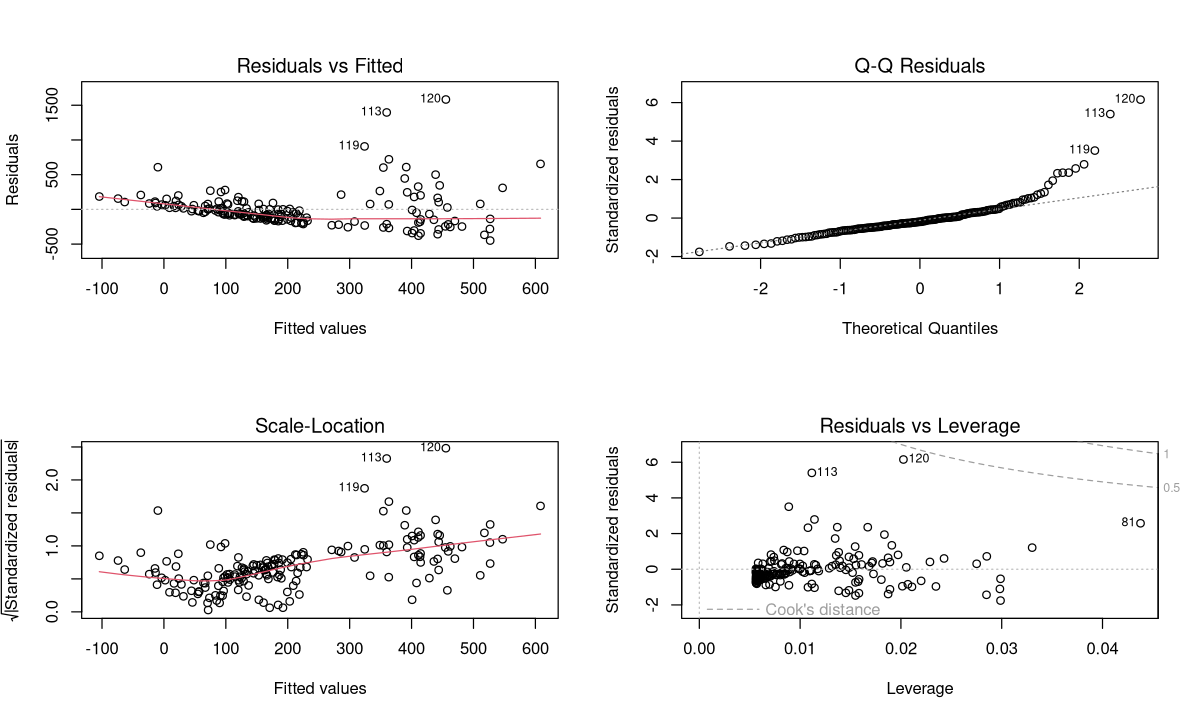

In [26]:
par(mfrow = c(2, 2))    # 2 lignes, 2 colonnes de graphes
plot(reg1)
par(mfrow = c(1, 1))

**Lecture (résolution + cheatsheet)** :
- *Residuals vs Fitted* : la moyenne des résidus par classe de prédictions **n'est pas toujours 0** et la dispersion **augmente** avec les valeurs prédites → **hétéroscédasticité**, homoscédasticité non vérifiée.
- *Normal Q-Q* : les points s'écartent de la droite dans la queue droite → distribution des résidus **asymétrique** avec trop de valeurs extrêmes → normalité non satisfaite.
- *Scale-Location* : pas plat, confirme l'hétéroscédasticité.
- *Residuals vs Leverage* : les observations 113, 120, 81 sont à surveiller.

### 2.7.2 Test de normalité de Shapiro-Wilk

> **Fonction R** : `shapiro.test(x)` — $H_0$ : *x suit une loi normale*. Renvoie la statistique **W** (entre 0 et 1 ; proche de 1 = proche de la normalité) et la **p-value**. Si $p > 0.05$, on ne rejette pas $H_0$ : les résidus peuvent être considérés comme normaux. (Utilisable pour $3 \le n \le 5000$.)

In [27]:
shapiro.test(resid(reg1))


	Shapiro-Wilk normality test

data:  resid(reg1)
W = 0.77396, p-value = 2.736e-15


$W = 0.774$ et $p = 2.7\times10^{-15} \ll 0.05$ → **normalité rejetée**, ce que confirme le Q-Q plot.

### 2.7.3 La distance de Cook
La **distance de Cook** $D_i$ mesure l'**influence** de l'observation $i$ : de combien changeraient toutes les prédictions si on retirait cette observation du modèle.

> **Complément** : $D_i = \dfrac{e_i^2}{(k+1)\,\hat\sigma^2}\cdot\dfrac{h_{ii}}{(1-h_{ii})^2}$ où $h_{ii}$ est l'effet levier (*leverage*) : une observation est influente si elle a un **grand résidu** et/ou un **grand levier** (x éloigné de $\bar x$).

Règles de lecture :
- si les distances sont **similaires pour toutes les observations** : pas de problème ;
- une distance **> 1** doit faire vérifier l'origine de l'échantillon (problème d'échantillonnage / erreur) ;
- seuil plus sévère souvent utilisé (et repris dans le homework) : $D_i > 4/n$.

120       113        81 
0.3913546 0.1648071 0.1521194

[1] 0

57  77  79  81  82  94 103 113 114 119 120 121 
 57  77  79  81  82  94 103 113 114 119 120 121

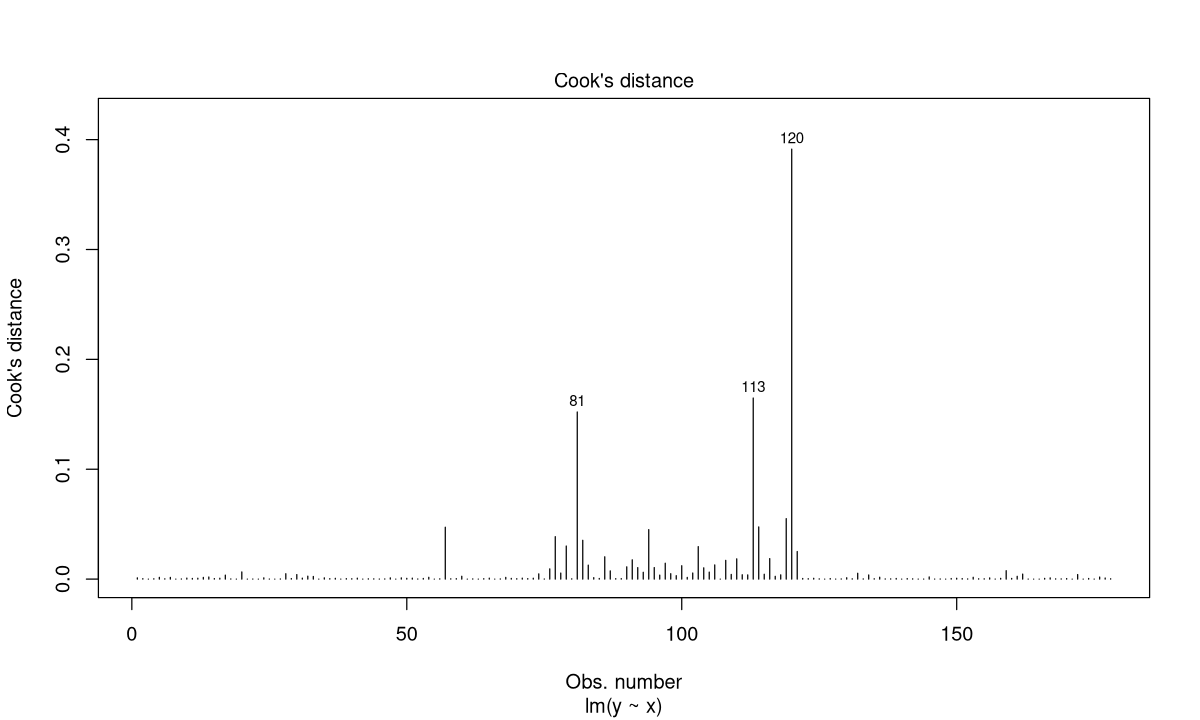

In [28]:
par(mfrow = c(1, 1))
plot(reg1, which = 4)            # "which = 4" : graphe des distances de Cook

cook1 <- cooks.distance(reg1)
head(sort(cook1, decreasing = TRUE), 3)   # les 3 plus influentes : 120, 113, 81
sum(cook1 > 1)                            # aucune > 1
which(cook1 > 4 / length(y))              # observations au-dessus de 4/n

Trois enregistrements (120, 113, 81) se détachent nettement : ce sont des **outliers potentiels**. Aucune distance ne dépasse 1.

![Analyse des résidus de reg1 (cheatsheet)](../Pasted%20image%2020261012141550.png)

*Figure de la cheatsheet : les mêmes 4 graphes obtenus dans RStudio.*

**Conclusion** : la régression univariée doit être modifiée. On peut étudier une **transformation de y** : en partie 1, la transformation **log10** donnait la distribution la plus symétrique.

### Exercice 2.7 : un graphe à la fois
1. Affiche uniquement le **Q-Q plot** de `reg1` (option `which`).
2. Reproduis ce Q-Q plot « à la main » avec `qqnorm()` et `qqline()` sur les résidus (comme dans `ex1.r`).
3. Affiche le graphe des résidus en fonction des valeurs prédites à la main avec `plot(fitted(reg1), resid(reg1))` et ajoute une ligne horizontale en 0.

In [29]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
plot(reg1, which = 2)

qqnorm(residuals(reg1), main = "Q-Q Plot des résidus")
qqline(residuals(reg1), col = "red", lwd = 2)

plot(fitted(reg1), resid(reg1), xlab = "Valeurs prédites", ylab = "Résidus")
abline(h = 0, col = "red", lty = 2)
```

Remarque : `plot(reg1, which = 2)` utilise les résidus **standardisés** (divisés par leur écart-type estimé), `qqnorm` les résidus bruts : la forme est la même, seule l'échelle change.

</details>

---
## 2.8 Transformation log10 de la lactoferrine

On teste une régression sur $\log_{10}(y)$ — la transformation qui symétrisait la distribution. On peut écrire la transformation **directement dans la formule**.

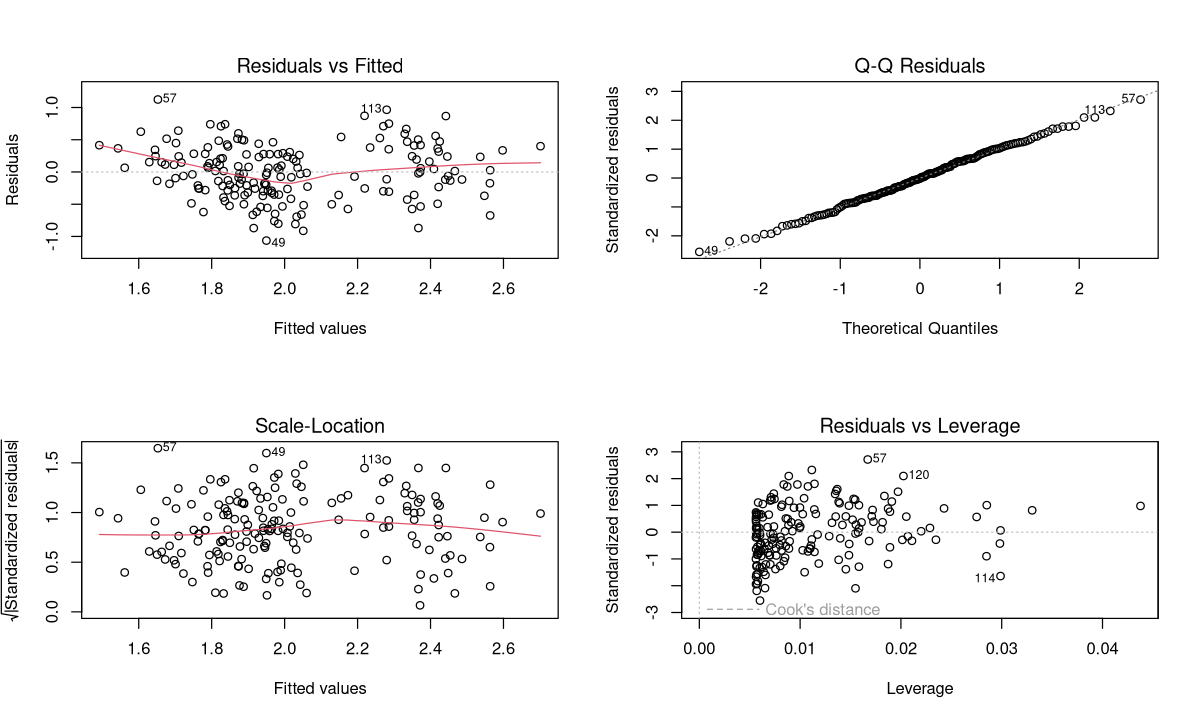

In [30]:
reg1b <- lm(log10(y) ~ x)
par(mfrow = c(2, 2))
plot(reg1b)
par(mfrow = c(1, 1))

In [31]:
shapiro.test(resid(reg1b))


	Shapiro-Wilk normality test

data:  resid(reg1b)
W = 0.99693, p-value = 0.9781


« *Without any doubt, the obtained results are better.* » (résolution)
- Q-Q : les résidus standardisés sont **alignés sur la droite** ;
- *Residuals vs Fitted* et *Scale-Location* : la moyenne des résidus tourne autour de 0, dispersion homogène ;
- Shapiro : $W = 0.9969$, $p = 0.978 > 0.05$ → **résidus normaux**.

La transformation est donc **pertinente**.

57        120        114 
0.06260019 0.04548760 0.04139742

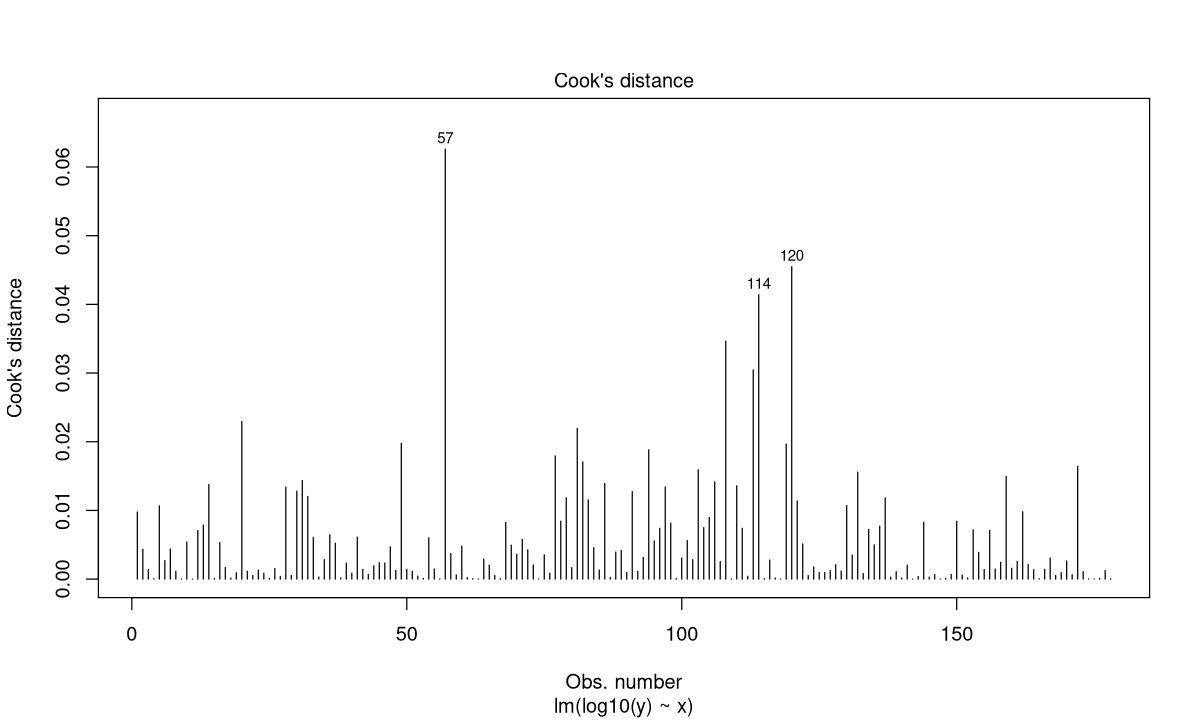

In [32]:
plot(reg1b, which = 4)
head(sort(cooks.distance(reg1b), decreasing = TRUE), 3)

Les distances de Cook sont maintenant **beaucoup plus petites** (max ≈ 0.06 contre 0.39) et plus homogènes ; les échantillons **57, 114 et 120** se distinguent légèrement.

In [33]:
summary(reg1b)


Call:
lm(formula = log10(y) ~ x)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.06389 -0.28718 -0.00666  0.28177  1.12397 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   3.1502     0.1388  22.690  < 2e-16 ***
x             6.3734     0.7628   8.356 1.89e-14 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.4176 on 176 degrees of freedom
Multiple R-squared:  0.284,	Adjusted R-squared:  0.2799 
F-statistic: 69.82 on 1 and 176 DF,  p-value: 1.894e-14


| Modèle | Intercept | Pente | RSE | R² | R² ajusté | Shapiro p |
|---|---|---|---|---|---|---|
| `reg1` : y ~ V713 | 872.6 | 3755 | 259.9 mg/L | 0.2623 | 0.2581 | 2.7e-15 |
| `reg1b` : log10(y) ~ V713 | 3.15 | 6.373 | 0.4176 (log10) | **0.284** | **0.2799** | **0.978** |

Le $R^2$ est amélioré par rapport à la régression sans transformation.

> **Attention — unités** : avec `reg1b`, les prédictions et le RSE sont en **log10(mg/L)**. Pour revenir en mg/L, il faut **rétro-transformer** : $\hat y = 10^{\widehat{\log_{10} y}}$. On ne peut pas comparer directement le RSE de `reg1` (259.9 mg/L) à celui de `reg1b` (0.4176 log10).

In [34]:
pred_log <- fitted(reg1b)               # prédictions en log10
pred_mgL <- 10^pred_log                 # rétro-transformation en mg/L
head(cbind(observe = y[, 1], pred_reg1 = fitted(reg1), pred_reg1b = pred_mgL), 5)

# Ecart-type des erreurs en mg/L après rétro-transformation (pour comparer avec reg1)
sqrt(sum((pred_mgL - y)^2) / reg1b$df.residual)

,observe,pred_reg1,pred_reg1b
1,16.2369,178.3581,93.71724
2,185.3267,102.0020,69.53696
3,193.2967,192.2776,98.95683
4,125.7756,215.9673,108.55649
5,16.6313,212.2875,107.00642


[1] 277.8089

### Exercice 2.8 : et la racine carrée ?
Ajuste `reg1c <- lm(sqrt(y) ~ x)`, fais le test de Shapiro sur ses résidus et compare son $R^2$ avec ceux de `reg1` et `reg1b`. Quelle transformation retiens-tu ?

In [35]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
reg1c <- lm(sqrt(y) ~ x)
shapiro.test(resid(reg1c))
c(reg1 = summary(reg1)$r.squared, reg1b = summary(reg1b)$r.squared,
  reg1c = summary(reg1c)$r.squared)
```

Surprise : le $R^2$ de `reg1c` (≈ 0.31) est même **supérieur** à celui de `reg1b` (0.284)… mais ses résidus restent **non normaux** (Shapiro p ≈ 1.7e-07 < 0.05) : les tests et p-values du modèle ne sont donc pas fiables. Le **log10** est la seule transformation qui satisfait les conditions d'application : c'est elle qu'on retient (comme dans la résolution). Morale : **on ne choisit pas un modèle sur le seul R²**, l'analyse des résidus est indispensable. (Et attention, les $R^2$ portent sur des échelles de y différentes.)

</details>

### Exercice 2.9 : combien d'observations influentes ?
Pour `reg1b`, compte le nombre d'observations dont la distance de Cook dépasse $4/n$. Réajuste ensuite le modèle **sans** ces observations (argument `subset` de `lm`, ou indices négatifs) et compare le $R^2$.

In [36]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
cook_b <- cooks.distance(reg1b)
infl <- which(cook_b > 4 / length(y))
length(infl); infl
reg1b_sans <- lm(log10(y[-infl]) ~ x[-infl])
c(avec = summary(reg1b)$r.squared, sans = summary(reg1b_sans)$r.squared)
```

Le $R^2$ augmente quand on retire les observations influentes… mais **attention** : retirer des points uniquement parce qu'ils « gênent » le modèle est dangereux. Une observation ne doit être supprimée que si l'on a une raison (erreur de mesure, d'encodage, échantillon hors population — cf. partie 1). Sinon, on surestime la qualité du modèle.

</details>

---
## 2.9 Généraliser `lm()` : formules, prédiction, intervalles

### 2.9.1 La syntaxe des formules

| Formule | Modèle |
|---|---|
| `y ~ x` | $y = a + bx + e$ |
| `y ~ x - 1` ou `y ~ 0 + x` | sans intercept : $y = bx + e$ |
| `log10(y) ~ x` | transformation de y dans la formule |
| `y ~ x + I(x^2)` | `I()` protège l'opération arithmétique (polynôme, partie 3) |
| `y ~ x1 + x2` | deux variables (régression multivariée, partie 3) |
| `y ~ .` | toutes les autres colonnes de `data` comme explicatives |
| `y ~ X` (X matrice) | une variable par colonne de la matrice (utilisé dans la résolution) |

### 2.9.2 Fonctions qui exploitent un objet `lm`

| Fonction | Renvoie |
|---|---|
| `coef(m)` | les coefficients |
| `fitted(m)` / `m$fitted.values` | les valeurs prédites $\hat y$ |
| `resid(m)` / `residuals(m)` | les résidus |
| `m$df.residual` | degrés de liberté résiduels $n-k-1$ |
| `summary(m)$r.squared`, `$adj.r.squared`, `$sigma`, `$coefficients` | R², R² ajusté, RSE, tableau des coefficients |
| `confint(m, level = 0.95)` | intervalles de confiance des coefficients |
| `predict(m, newdata, interval = "confidence"/"prediction")` | prédictions pour de nouvelles données |
| `anova(m)` | table d'analyse de la variance (test F) |
| `AIC(m)`, `BIC(m)` | critères d'information (partie 4) |
| `cooks.distance(m)`, `hatvalues(m)`, `rstandard(m)` | influence, leviers, résidus standardisés |

In [37]:
confint(reg1b)        # IC à 95 % des coefficients
anova(reg1b)          # SCE expliquée (x) et résiduelle

,2.5 %,97.5 %
(Intercept),2.876184,3.424172
x,4.868066,7.878801


,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
x,1,12.17454,12.1745388,69.81542,1.894345e-14
Residuals,176,30.69120,0.1743818,NA,NA


### 2.9.3 Prédire de nouveaux échantillons avec `predict()`

> **Fonction R** : `predict(objet_lm, newdata, interval = c("none", "confidence", "prediction"), level = 0.95)`
> - `newdata` : un **data.frame** dont les colonnes portent **les mêmes noms** que les variables de la formule ;
> - `interval = "confidence"` : intervalle pour la **moyenne** de y à ce x ; `"prediction"` : intervalle pour **une nouvelle observation** (plus large).

Pour `predict`, il est plus propre d'ajuster le modèle avec un `data.frame` et des noms de colonnes explicites :

In [38]:
df_lacto <- data.frame(lacto = lactoferrin$V1062, V713 = lactoferrin$V713)
reg1b_df <- lm(log10(lacto) ~ V713, data = df_lacto)

nouveaux <- data.frame(V713 = c(-0.20, -0.18, -0.15))   # 3 nouveaux spectres (absorbance en V713)
p <- predict(reg1b_df, newdata = nouveaux, interval = "prediction")
p                       # en log10
round(10^p, 1)          # en mg/L (bornes rétro-transformées)

,fit,lwr,upr
1,1.875491,1.048346,2.702637
2,2.002960,1.176509,2.829411
3,2.194163,1.366699,3.021627


,fit,lwr,upr
1,75.1,11.2,504.2
2,100.7,15.0,675.2
3,156.4,23.3,1051.1


### Exercice 2.10 : modèle sans intercept
Ajuste sur les données méthane le modèle **sans intercept** `CH4 ~ FA4_6 - 1`. Vérifie que la pente vaut $\sum x_i y_i / \sum x_i^2$ (résoudre l'unique équation normale $\partial f/\partial b = 0$ avec $a = 0$). Ce modèle est-il pertinent ici ?

In [39]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
reg0 <- lm(CH4 ~ FA4_6 - 1, data = methane)
coef(reg0)
with(methane, sum(FA4_6 * CH4) / sum(FA4_6^2))
plot(methane$FA4_6, methane$CH4, xlim = c(0, 6), ylim = c(0, 800))
abline(reg0, col = "red"); abline(reg_ch4, col = "blue", lty = 2)
```

Sans intercept, la droite est forcée de passer par l'origine. Comme aucune vache n'a 0 % de FA4-FA6, cette contrainte n'a pas de sens biologique et dégrade l'ajustement : on garde l'intercept. (Le modèle sans intercept $y = \beta_1 x$ sera utilisé en partie 5 pour illustrer la fonction de coût.)

</details>

### Questions de compréhension

**Q1.** Vrai ou faux : « une corrélation de 0 entre x et y prouve qu'il n'existe aucune relation entre x et y ».

**Q2.** Un modèle a un $R^2$ de 0.80. Que signifie ce chiffre ?

**Q3.** Le *Residual standard error* de `reg1` vaut 259.9. Dans quelle unité ? Pourquoi divise-t-on par 176 ?

**Q4.** Pourquoi la p-value du test de Shapiro doit-elle être **supérieure** à 0.05 pour valider le modèle, alors que celle d'un coefficient doit être **inférieure** à 0.05 ?

**Q5.** Pourquoi ne peut-on pas comparer directement le RSE de `reg1` et celui de `reg1b` ?

<details>
<summary><b>Voir les réponses</b></summary>

**Q1.** **Faux.** $r$ ne mesure que le lien **linéaire**. Une relation parfaitement parabolique ($y = x^2$ avec x symétrique autour de 0) donne $r \approx 0$.

**Q2.** 80 % de la variabilité (somme des carrés des écarts) de y est expliquée par le modèle ; 20 % reste inexpliquée (résiduelle). Ça ne dit rien de la causalité ni de la validité des hypothèses.

**Q3.** En mg/L (unité de y). On divise par les degrés de liberté $n - k - 1 = 178 - 1 - 1 = 176$ (deux paramètres estimés).

**Q4.** Les hypothèses nulles sont différentes : pour Shapiro, $H_0$ = « normalité » : on **veut ne pas la rejeter** ($p > 0.05$). Pour un coefficient, $H_0$ = « coefficient nul » : on **veut la rejeter** ($p < 0.05$) pour conclure qu'il est significatif.

**Q5.** Ils ne sont pas dans la même unité : mg/L pour `reg1`, log10(mg/L) pour `reg1b`. Il faut rétro-transformer les prédictions de `reg1b` (`10^`) avant de comparer des erreurs.

</details>

---
## Récapitulatif

**Points clés**
- Modèle : $y_i = a + b x_i + e_i$ ; résidu $e_i = y_i - \hat y_i$.
- Moindres carrés : minimiser $\sum e_i^2$ → équations normales → $b = \frac{SPE}{SCE_x} = \frac{\mathrm{cov}(x,y)}{s^2_x}$, $a = \bar y - b \bar x$.
- $r = \frac{\mathrm{cov}(x,y)}{s_x s_y}\in[-1,1]$ (lien **linéaire**, pas de causalité) ; $R^2 = r^2$ = part de variance expliquée.
- $MSE = \frac{1}{n}\sum e_i^2 = s_y^2(1-r^2)$ ; $0 \le RMSE \le s_y$ ; R utilise $n-k-1$ (RSE, SEP).
- $R^2_{adj} = 1 - \frac{(1-R^2)(n-1)}{n-k-1}$ pour comparer des modèles de tailles différentes.
- Sélection intuitive de x parmi 1060 : **spectre de corrélation** → V713 ($r = 0.51$).
- Analyse des résidus **obligatoire** : 4 graphes, Shapiro ($p>0.05$ souhaité), Cook (> 1 ou > 4/n).
- Lactoferrine : résidus non normaux → **log10(y)** → résidus normaux, $R^2$ 0.262 → 0.284.

**Fonctions R vues**

| Fonction | Usage |
|---|---|
| `cor(X, y)`, `cov()`, `var()`, `sd()` | corrélation, covariance, variance, écart-type |
| `max(abs())`, `which.max()`, `order()` | trouver / classer les variables les plus corrélées |
| `as.matrix()` | convertir en matrice |
| `lm(formula, data)` | ajuster une régression linéaire |
| `summary()`, `coef()`, `fitted()`, `resid()`, `$df.residual` | exploiter le modèle |
| `plot(lm)`, `plot(lm, which = 4)` | graphes de résidus, distance de Cook |
| `shapiro.test()` | test de normalité |
| `cooks.distance()` | distances de Cook |
| `qqnorm()`, `qqline()` | Q-Q plot manuel |
| `predict(newdata, interval)`, `confint()`, `anova()` | prédiction, intervalles, ANOVA |
| `pander()`, `panderOptions()` | mise en forme (RMarkdown) |

**Partie suivante** : `03_Regression_lineaire_multivariee.ipynb` — utiliser **plusieurs** points spectraux, forme matricielle $y = X\beta + e$, sur-ajustement et colinéarité.